# Life-stage polities
Each individual gets a location for each stage of their life (early: birth → first work, active: first work → last work, late: last work → death), read from the first Wikidata field of the stage's priority list that matches a polity. The location is matched to a Cliopatria polity held during that stage, by its English Wikipedia link first and by its coordinates otherwise. This notebook runs on a sample, before any ingestion.

In [1]:
import json
import sys
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import polars as pl
from shapely import STRtree, from_geojson, make_valid, points
from tqdm.auto import tqdm

sys.path.insert(0, '../notebooks_analysis')
from style import *

apply_style()

DB_PATH = '../../data/cultura/cultura_enriched_v3.2.duckdb'  # read only
LIFE_LOCATIONS = Path('../../data/raw_data_from_wikidata/wikidata_extraction_scripts_v2/life_locations')
SAMPLE_SIZE = 10_000
SEED = 42

PROPERTIES = {'P937': 'work_location', 'P551': 'residence', 'P108': 'employer', 'P69': 'educated_at', 'P39': 'position_held'}
SOURCE_LABELS = {
    'place_of_birth': 'Place of birth (P19)',
    'educated_at': 'Educated at (P69)',
    'residence': 'Residence (P551)',
    'country_of_citizenship': 'Country of citizenship (P27)',
    'work_location': 'Work location (P937)',
    'employer': 'Employer (P108)',
    'position_held': 'Position held (P39)',
    'place_of_death': 'Place of death (P20)',
}
STAGES = {'early': ('birth', 'first_work'), 'active': ('first_work', 'last_work'), 'late': ('last_work', 'death')}
RULES = {
    'early': [('place_of_birth', 'certain'), ('educated_at', 'certain'), ('residence', 'unsure'), ('country_of_citizenship', 'unsure'), ('work_location', 'unsure'), ('employer', 'unsure'), ('position_held', 'unsure'), ('place_of_death', 'unsure')],
    'active': [('work_location', 'certain'), ('employer', 'certain'), ('position_held', 'certain'), ('residence', 'certain'), ('educated_at', 'unsure'), ('country_of_citizenship', 'unsure'), ('place_of_birth', 'unsure'), ('place_of_death', 'unsure')],
    'late': [('place_of_death', 'certain'), ('residence', 'unsure'), ('work_location', 'unsure'), ('position_held', 'unsure'), ('employer', 'unsure'), ('country_of_citizenship', 'unsure'), ('educated_at', 'unsure'), ('place_of_birth', 'unsure')],
}
METHODS = ['link', 'coordinates']  # the Wikipedia link is always tried before the coordinates
CERTAINTY_COLORS = {'certain': BLUE, 'unsure': LIGHT_ORANGE, 'none': PALE_GREY}

pl.Config.set_tbl_rows(30)
pl.Config.set_fmt_str_lengths(90)
pl.Config.set_tbl_width_chars(250)

/Users/charlesdedampierre/Desktop/Rsearch Folder/cultura/cultura_database/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


polars.config.Config

## Data
### Sample
Individuals with a birth, a first work, a last work and a death year, so that the three stages are defined. The sample is drawn by a seeded hash of the qid, so it is the same on every run.

In [2]:
connection = duckdb.connect(DB_PATH, read_only=True)
sample = connection.sql(f'''
    WITH dated AS (
        SELECT entity.qid AS qid, entity.label_en AS name, birth_date.year AS birth, first_work_date.year AS first_work,
               last_work_date.year AS last_work, death_date.year AS death
        FROM individual_enriched
        WHERE birth_date.year IS NOT NULL AND first_work_date.year IS NOT NULL
          AND last_work_date.year IS NOT NULL AND death_date.year IS NOT NULL
        ORDER BY hash(qid || '{SEED}')
        LIMIT {SAMPLE_SIZE}
    )
    SELECT dated.*,
           individual.place_of_birth.entity.qid AS place_of_birth,
           individual.place_of_death.entity.qid AS place_of_death,
           list_transform(individual.country_of_citizenship, country -> country.entity.qid) AS country_of_citizenship
    FROM dated JOIN individual ON individual.entity.qid = dated.qid
''').pl().sort('qid')
assert sample['qid'].is_unique and sample.height == SAMPLE_SIZE
print(f'{sample.height:,} individuals')
print(f"stages in the wrong order: {sample.filter((pl.col('first_work') < pl.col('birth')) | (pl.col('last_work') < pl.col('first_work')) | (pl.col('death') < pl.col('last_work'))).height:,}")
sample.sample(5, seed=SEED)

10,000 individuals
stages in the wrong order: 32


qid,name,birth,first_work,last_work,death,place_of_birth,place_of_death,country_of_citizenship
str,str,i64,i64,i64,i64,str,str,list[str]
"""Q75257947""","""Marcus Michael Hartigan""",1879,1919,1935,1948,null,null,"[""Q174193""]"
"""Q134958863""","""Mario Overhoff""",1928,1969,2000,2005,"""Q1741""","""Q43196""","[""Q16"", ""Q30"", ""Q40""]"
"""Q969199""","""Teodor Jung""",1892,1927,1927,1986,"""Q12464""","""Q36600""","[""Q183"", ""Q29999""]"
"""Q56025763""","""Lucy Conklin""",1885,1953,1953,1954,null,null,[]
"""Q703439""","""Jana Ueekata""",1549,1586,1603,1611,"""Q2591805""",null,"[""Q28025""]"


### Life-location statements
Work location, residence, employer, educated at and position held of the sampled individuals, as extracted by `26_extract_life_locations.py`; deprecated statements are dropped.

In [3]:
statements = connection.sql(f'''
    SELECT qid, property, target
    FROM read_json('{LIFE_LOCATIONS}/parts/statements/*.json', columns = {{qid: 'VARCHAR', property: 'VARCHAR', target: 'VARCHAR', rank: 'VARCHAR'}})
    WHERE rank <> 'deprecated' AND qid IN (SELECT qid FROM sample)
''').pl().with_columns(source=pl.col('property').replace_strict(PROPERTIES))
print(f'{statements.height:,} statements for {statements["qid"].n_unique():,} sampled individuals')
statements.group_by('source').agg(pl.len().alias('statements'), pl.col('qid').n_unique().alias('individuals')).sort('individuals', descending=True)

7,472 statements for 3,486 sampled individuals


source,statements,individuals
str,u32,u32
"""educated_at""",2313,1669
"""position_held""",2602,1314
"""employer""",1107,754
"""work_location""",851,614
"""residence""",599,509


### Every location of each individual
One list of qids per field. Birthplace, deathplace and citizenship come from the database; the five other fields from the statements.

In [4]:
held = statements.group_by('qid', 'source').agg(pl.col('target').unique(maintain_order=True)).pivot(on='source', index='qid', values='target')
people = sample.join(held, on='qid', how='left').with_columns(
    pl.col('place_of_birth', 'place_of_death').map_elements(lambda qid: [qid], return_dtype=pl.List(pl.String)),
)
people = people.with_columns(pl.col(source).fill_null([]) for source in SOURCE_LABELS)
assert people.height == sample.height
people.select('qid', 'name', *SOURCE_LABELS).sample(5, seed=SEED)

qid,name,place_of_birth,educated_at,residence,country_of_citizenship,work_location,employer,position_held,place_of_death
str,str,list[str],list[str],list[str],list[str],list[str],list[str],list[str],list[str]
"""Q75257947""","""Marcus Michael Hartigan""",[],[],[],"[""Q174193""]",[],[],[],[]
"""Q134958863""","""Mario Overhoff""","[""Q1741""]","[""Q1067935"", ""Q201492""]",[],"[""Q16"", ""Q30"", ""Q40""]",[],[],[],"[""Q43196""]"
"""Q969199""","""Teodor Jung""","[""Q12464""]",[],[],"[""Q183"", ""Q29999""]",[],[],[],"[""Q36600""]"
"""Q56025763""","""Lucy Conklin""",[],[],[],[],[],[],[],[]
"""Q703439""","""Jana Ueekata""","[""Q2591805""]",[],[],"[""Q28025""]",[],[],"[""Q2378691""]",[]


### Where each location is
A location is tested at one or more spots. A place (birthplace, deathplace, citizenship, work location, residence) is its own spot; an employer or a school is tested at its own coordinates, then at the places it is in (P131 / P159 / P276); a position held is tested at its jurisdiction (P1001). Each spot carries its English Wikipedia link (from the Place table) and its coordinates (Place table, else the extraction).

In [5]:
targets = json.loads((LIFE_LOCATIONS / 'targets.json').read_text())
place_rows = connection.sql('SELECT entity.qid, entity.label_en, sitelink.url, coordinates.longitude, coordinates.latitude FROM place').fetchall()
label = {qid: target['label_en'] for qid, target in targets.items() if target['label_en']}  # the Place table has double-encoded labels
link = {qid: url for qid, _, url, _, _ in place_rows if url}
point = {qid: (longitude, latitude) for qid, _, _, longitude, latitude in place_rows if latitude is not None}
for qid, name, _, _, _ in place_rows:
    if name:
        label.setdefault(qid, name)
for qid, target in targets.items():
    for spot, coordinates in [(qid, target['coordinates']), *target['located_in'].items(), *target['jurisdiction'].items()]:
        if coordinates:
            point.setdefault(spot, (coordinates['longitude'], coordinates['latitude']))
print(f'{len(link):,} spots with a link, {len(point):,} with coordinates')


def spots(source, qid):
    target = targets.get(qid, {})
    if source in ('employer', 'educated_at'):
        return [qid, *target.get('located_in', {})]
    if source == 'position_held':
        return list(target.get('jurisdiction', {}))
    return [qid]

233,386 spots with a link, 468,816 with coordinates


### Polities
Every dated Cliopatria territory, its polity and its English Wikipedia link. The few invalid polygons are repaired.

In [6]:
territories = connection.sql('''
    SELECT cliopatria_id, name, sitelink.url AS url, territory.start_year AS start_year, territory.end_year AS end_year, territory.geometry AS geometry
    FROM polity, unnest(territories) AS t(territory)
    WHERE territory.start_year IS NOT NULL AND territory.end_year IS NOT NULL AND territory.geometry IS NOT NULL
''').pl()
geometries = make_valid(from_geojson(territories['geometry'].to_list()))
tree = STRtree(geometries)
polity_of = list(zip(territories['cliopatria_id'], territories['name']))
start_of, end_of = territories['start_year'].to_list(), territories['end_year'].to_list()
by_link = {}
for index, url in enumerate(territories['url']):
    if url:
        by_link.setdefault(url, []).append(index)
print(f'{territories.height:,} territories of {territories["cliopatria_id"].n_unique():,} polities, {len(by_link):,} polity links')
territories.drop('geometry').sample(5, seed=SEED)

13,755 territories of 1,604 polities, 1,462 polity links


cliopatria_id,name,url,start_year,end_year
i64,str,str,i64,i64
988,"""Portuguese Empire""","""https://en.wikipedia.org/wiki/Portuguese_Empire""",1772,1774
251,"""Baekje""","""https://en.wikipedia.org/wiki/Baekje""",395,475
1097,"""British Empire""","""https://en.wikipedia.org/wiki/British_Empire""",1781,1782
672,"""Duchies of Poland""","""https://en.wikipedia.org/wiki/Testament_of_Boles%C5%82aw_III_Wrymouth""",1210,1215
169,"""Han Dynasty""","""https://en.wikipedia.org/wiki/Han_dynasty""",-77,-51


Every spot of the sample with coordinates is placed in the territories containing it, in one vectorised query.

In [7]:
sample_spots = sorted({spot for source in SOURCE_LABELS for qids in people[source] for qid in qids for spot in spots(source, qid) if spot in point})
spot_index, territory_index = tree.query(points([point[spot] for spot in sample_spots]), predicate='within')
containing = {}
for spot, territory in zip(spot_index, territory_index):
    containing.setdefault(sample_spots[spot], []).append(int(territory))
print(f'{len(sample_spots):,} spots with coordinates, {len(containing):,} inside at least one territory')

7,979 spots with coordinates, 7,726 inside at least one territory


## Assignment
For each stage, the fields are tried in the stage's order. For every location of a field, its spots are tested by link, then by coordinates: a territory matches when it held the spot during the stage. The first field with a match ends the search; all its locations are kept. Each polity gets the years of the stage it held, each year counted once, longest first. `tried` lists the fields that had a location but no polity before the chosen one.

In [8]:
def polities_held(indices, start, end):
    years = {}
    for index in indices:
        low, high = max(start_of[index], start), min(end_of[index], end)
        if low <= high:
            years.setdefault(polity_of[index], set()).update(range(low, high + 1))
    return {polity: len(covered) for polity, covered in years.items()}


def locate(source, qid, start, end):
    for method in METHODS:
        for spot in spots(source, qid):
            indices = by_link.get(link.get(spot), []) if method == 'link' else containing.get(spot, [])
            found = polities_held(indices, start, end)
            if found:
                return method, spot, found
    return None


def assign(person, stage):
    start, end = person[STAGES[stage][0]], person[STAGES[stage][1]]
    tried = []
    for source, certainty in RULES[stage]:
        located = [hit for qid in person[source] if (hit := locate(source, qid, start, end))]
        if located:
            polities = {}
            for _, _, found in located:
                for polity, years in found.items():
                    polities[polity] = max(years, polities.get(polity, 0))
            ranked = sorted(polities.items(), key=lambda pair: -pair[1])
            return {
                'rule': SOURCE_LABELS[source], 'certainty': certainty,
                'method': ' + '.join(sorted({method for method, _, _ in located})),
                'location': '; '.join(sorted({label.get(spot, spot) for _, spot, _ in located})),
                'polities': [name for (_, name), _ in ranked], 'years': [years for _, years in ranked], 'tried': tried,
            }
        if person[source]:
            tried.append(SOURCE_LABELS[source])
    return {'rule': None, 'certainty': 'none', 'method': None, 'location': None, 'polities': [], 'years': [], 'tried': tried}


rows = []
for person in tqdm(people.iter_rows(named=True), total=people.height, desc='individuals'):
    for stage, (start, end) in STAGES.items():
        rows.append({'qid': person['qid'], 'stage': stage, 'start': person[start], 'end': person[end], **assign(person, stage)})
assignments = pl.DataFrame(rows, schema_overrides={'polities': pl.List(pl.String), 'years': pl.List(pl.Int64), 'tried': pl.List(pl.String)})
assert assignments.height == 3 * people.height
assignments.filter(pl.col('certainty') != 'none').sample(10, seed=SEED)

individuals: 100%|██████████| 10000/10000 [00:02<00:00, 3667.91it/s]


qid,stage,start,end,rule,certainty,method,location,polities,years,tried
str,str,i64,i64,str,str,str,str,list[str],list[i64],list[str]
"""Q6227374""","""late""",1994,2013,"""Place of death (P20)""","""certain""","""coordinates""","""Anchorage""","[""United States of America""]",[20],[]
"""Q136324523""","""active""",1899,1920,"""Country of citizenship (P27)""","""unsure""","""link""","""United States""","[""United States of America""]",[22],[]
"""Q96679645""","""early""",1869,1901,"""Place of birth (P19)""","""certain""","""coordinates""","""SÃ¶dra SÃ¤m""","[""United Kingdoms of Sweden and Norway""]",[33],[]
"""Q4980210""","""early""",1909,1944,"""Place of birth (P19)""","""certain""","""coordinates""","""Fulham""","[""British Empire"", ""Kingdom of Great Britain""]","[36, 36]",[]
"""Q6077025""","""active""",1998,2012,"""Educated at (P69)""","""unsure""","""coordinates""","""Army War Institute; Turkish Military Academy""","[""Republic of Turkey""]",[15],[]
"""Q3289327""","""early""",1860,1900,"""Place of birth (P19)""","""certain""","""coordinates""","""Toucy""","[""French Third Republic"", ""Second French Empire""]","[30, 11]",[]
"""Q111434531""","""active""",1773,1795,"""Place of birth (P19)""","""unsure""","""coordinates""","""Turin""","[""Kingdom of Sardinia""]",[23],"[""Country of citizenship (P27)""]"
"""Q35849494""","""late""",1975,2008,"""Place of death (P20)""","""certain""","""coordinates""","""Toulouse""","[""French Fifth Republic""]",[34],[]
"""Q11960794""","""late""",1944,1950,"""Work location (P937)""","""unsure""","""coordinates""","""Kvarven Fort""","[""Kingdom of Norway"", ""Nazi Germany""]","[6, 1]",[]


## Results
### Matched share per stage

In [9]:
assignments.group_by('stage').agg(
    pl.len().alias('individuals'),
    (pl.col('certainty') == 'certain').sum().alias('certain'),
    (pl.col('certainty') == 'unsure').sum().alias('unsure'),
    ((pl.col('certainty') == 'none') & (pl.col('tried').list.len() == 0)).sum().alias('no_location'),
    ((pl.col('certainty') == 'none') & (pl.col('tried').list.len() > 0)).sum().alias('location_but_no_polity'),
    (100 * (pl.col('certainty') != 'none').mean()).round(1).alias('matched_%'),
    (100 * (pl.col('polities').list.len() > 1).mean()).round(1).alias('several_polities_%'),
).sort(pl.col('stage').cast(pl.Enum(list(STAGES))))

stage,individuals,certain,unsure,no_location,location_but_no_polity,matched_%,several_polities_%
str,u32,u32,u32,u32,u32,f64,f64
"""early""",10000,5309,2062,2507,122,73.7,41.4
"""active""",10000,2220,5151,2507,122,73.7,26.6
"""late""",10000,3891,3468,2507,134,73.6,21.5


### Figure 1: certainty of the stage polity

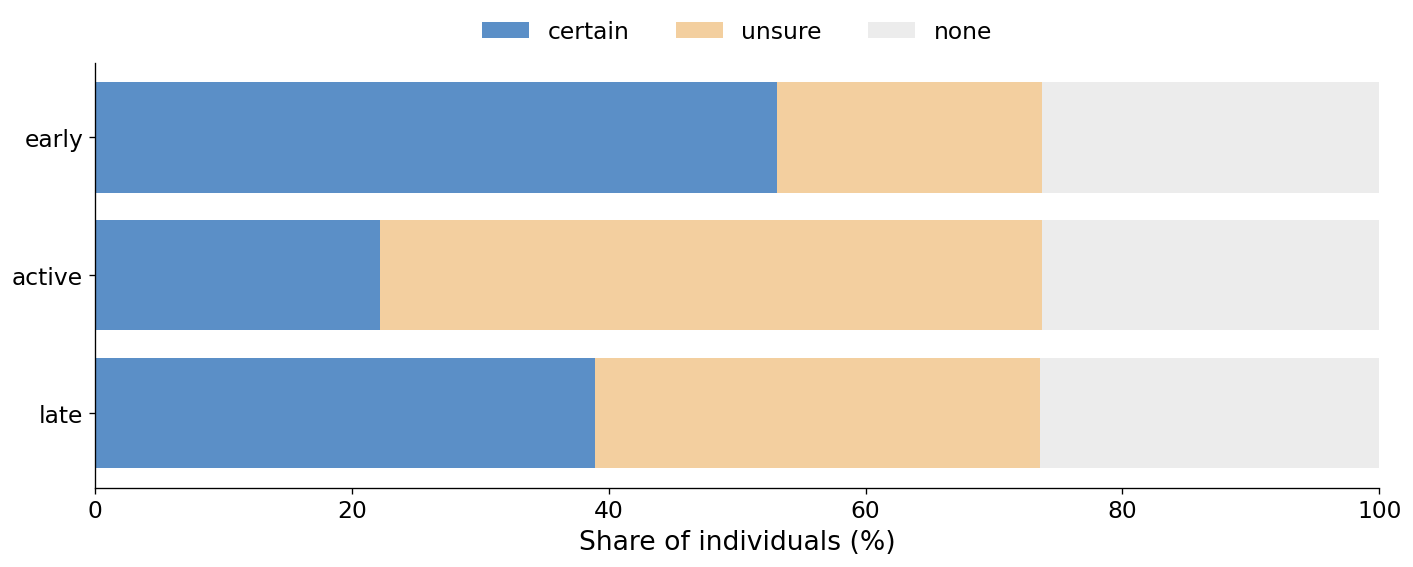

In [10]:
shares = (
    assignments.group_by('stage', 'certainty').len()
    .with_columns((100 * pl.col('len') / pl.col('len').sum().over('stage')).alias('share'))
)
fig, ax = plt.subplots(figsize=FIGSIZE)
stages = list(STAGES)[::-1]
left = [0.0] * len(stages)
for certainty, color in CERTAINTY_COLORS.items():
    values = [shares.filter((pl.col('stage') == stage) & (pl.col('certainty') == certainty))['share'].sum() for stage in stages]
    ax.barh(stages, values, left=left, color=color, label=certainty)
    left = [a + b for a, b in zip(left, values)]
ax.set_xlabel('Share of individuals (%)', fontsize=16)
ax.set_xlim(0, 100)
ax.tick_params(labelsize=14)
ax.grid(axis='y', visible=False)
ax.legend(fontsize=14, frameon=False, ncol=3, loc='upper center', bbox_to_anchor=(0.5, 1.15))
plt.tight_layout()
plt.show()

### Rule chosen per stage
Share of the individuals of each stage settled by each field and method.

In [11]:
rule_order = list(SOURCE_LABELS.values())
(
    assignments.with_columns(rule=pl.col('rule').fill_null('no polity'), method=pl.col('method').fill_null(''))
    .group_by('stage', 'rule', 'certainty', 'method').len()
    .with_columns((100 * pl.col('len') / pl.col('len').sum().over('stage')).round(2).alias('share_%'))
    .sort(pl.col('stage').cast(pl.Enum(list(STAGES))), 'len', descending=[False, True])
)

stage,rule,certainty,method,len,share_%
str,str,str,str,u32,f64
"""early""","""Place of birth (P19)""","""certain""","""coordinates""",4905,49.05
"""early""","""no polity""","""none""","""""",2629,26.29
"""early""","""Country of citizenship (P27)""","""unsure""","""link""",847,8.47
"""early""","""Country of citizenship (P27)""","""unsure""","""coordinates""",586,5.86
"""early""","""Educated at (P69)""","""certain""","""coordinates""",371,3.71
"""early""","""Residence (P551)""","""unsure""","""coordinates""",292,2.92
"""early""","""Place of death (P20)""","""unsure""","""coordinates""",164,1.64
"""early""","""Country of citizenship (P27)""","""unsure""","""coordinates + link""",78,0.78
"""early""","""Work location (P937)""","""unsure""","""coordinates""",43,0.43


### Matched share by century of birth

In [12]:
(
    assignments.join(sample.select('qid', 'birth'), on='qid')
    .with_columns(period=pl.col('birth').cut([1000, 1500, 1800, 1900], labels=['before 1000', '1000–1499', '1500–1799', '1800–1899', '1900 and after']))
    .group_by('period', 'stage')
    .agg((100 * (pl.col('certainty') != 'none').mean()).round(1).alias('matched_%'), pl.col('qid').n_unique().alias('individuals'))
    .pivot(on='stage', index=['period', 'individuals'], values='matched_%')
    .sort('period')
)

period,individuals,early,active,late
cat,u32,f64,f64,f64
"""1000–1499""",218,63.8,63.3,60.6
"""1500–1799""",1594,58.3,58.3,58.3
"""1800–1899""",4313,72.5,72.5,72.5
"""1900 and after""",3802,82.5,82.5,82.5
"""before 1000""",73,53.4,53.4,46.6


## Per individual
One row per individual: for each stage, the polities with their years and the rule that chose them.

In [13]:
def describe(row):
    if not row['polities']:
        return 'no polity'
    return '; '.join(f'{name} ({years}y)' for name, years in zip(row['polities'], row['years']))


per_stage = assignments.with_columns(
    polity=pl.struct('polities', 'years').map_elements(describe, return_dtype=pl.String),
    chosen=pl.concat_str(pl.col('rule'), pl.col('method'), pl.col('certainty'), separator=' · ').fill_null('—'),
)
per_individual = sample.select('qid', 'name', 'birth', 'first_work', 'last_work', 'death')
for stage in STAGES:
    per_individual = per_individual.join(
        per_stage.filter(pl.col('stage') == stage).select('qid', pl.col('polity').alias(f'{stage}_polity'), pl.col('chosen').alias(f'{stage}_rule')),
        on='qid',
    )
assert per_individual.height == SAMPLE_SIZE
per_individual.sample(25, seed=SEED)

qid,name,birth,first_work,last_work,death,early_polity,early_rule,active_polity,active_rule,late_polity,late_rule
str,str,i64,i64,i64,i64,str,str,str,str,str,str
"""Q75244166""","""Ethel Mary Yerburgh""",1880,1913,1935,1965,"""no polity""","""—""","""no polity""","""—""","""no polity""","""—"""
"""Q134709335""","""John Joseph Brice""",1921,1958,1965,1965,"""no polity""","""—""","""no polity""","""—""","""no polity""","""—"""
"""Q96492""","""Axel von Freytagh-Loringhoven""",1878,1918,1934,1942,"""Russian Empire (39y); German Empire (2y)""","""Place of birth (P19) · coordinates · certain""","""Weimar Republic (15y); German Empire (2y)""","""Work location (P937) · coordinates · certain""","""Nazi Germany (7y); Weimar Republic (2y)""","""Place of death (P20) · coordinates · certain"""
"""Q559527""","""Blessed Gerard""",1047,1095,1116,1120,"""Fatimid Caliphate (25y); Great Seljuk Empire (24y)""","""Place of death (P20) · coordinates · unsure""","""Kingdom of Jerusalem (18y); Great Seljuk Empire (4y)""","""Place of death (P20) · coordinates · unsure""","""Kingdom of Jerusalem (5y)""","""Place of death (P20) · coordinates · certain"""
"""Q6981134""","""Shemuel Yavneʼeli""",1884,1924,1940,1961,"""Russian Empire (33y); Union of Soviet Socialist Republics (3y); Republics of the Soviet Un…","""Place of birth (P19) · coordinates · certain""","""British Empire (17y); British Africa (13y); Kingdom of Great Britain (4y)""","""Country of citizenship (P27) · coordinates · unsure""","""State of Israel (14y)""","""Country of citizenship (P27) · link · unsure"""
"""Q39403408""","""Gustave Cauderlier""",1848,1884,1906,1916,"""no polity""","""—""","""no polity""","""—""","""no polity""","""—"""
"""Q111460993""","""Raivo Aljaste""",1939,1986,2003,2012,"""Union of Soviet Socialist Republics (44y); Nazi Germany (3y); Estonia (1y)""","""Place of birth (P19) · coordinates · certain""","""Republic of Estonia (12y); Union of Soviet Socialist Republics (6y)""","""Educated at (P69) · coordinates · unsure""","""Republic of Estonia (10y)""","""Place of death (P20) · coordinates · certain"""
"""Q431137""","""Jan Matsys""",1509,1514,1575,1575,"""Habsburg Monarchy (6y); House of Habsburg (6y)""","""Place of birth (P19) · coordinates · certain""","""Papal States (62y); Kingdom of France (62y); Personal union of Spanish Empire with Habsbur…","""Work location (P937) · coordinates · certain""","""Alliance between Papal States and Spanish Empire (1y); Spanish Empire (1y); Kingdom of Spa…","""Place of death (P20) · coordinates · certain"""
"""Q118762864""","""Johan Petter Lundeberg""",1767,1807,1816,1816,"""Swedish Empire (41y)""","""Place of birth (P19) · coordinates · certain""","""Swedish Empire (8y); United Kingdoms of Sweden and Norway (2y)""","""Country of citizenship (P27) · coordinates · unsure""","""United Kingdoms of Sweden and Norway (1y)""","""Country of citizenship (P27) · coordinates · unsure"""


### One individual in detail
`show(qid)` prints, for each stage, the window, the chosen rule, the location, the polities, and the fields tried before without a polity.

In [14]:
def show(qid):
    person = people.filter(pl.col('qid') == qid).row(0, named=True)
    print(f"{person['name']} ({qid})  born {person['birth']}, first work {person['first_work']}, last work {person['last_work']}, died {person['death']}")
    for row in assignments.filter(pl.col('qid') == qid).iter_rows(named=True):
        print(f"\n  {row['stage']:>6}  {row['start']} → {row['end']}")
        print(f"          rule      {row['rule'] or 'no polity'}" + (f"  [{row['certainty']}, by {row['method']}]" if row['rule'] else ''))
        if row['rule']:
            print(f"          location  {row['location']}")
            print(f"          polities  {describe(row)}")
        if row['tried']:
            print(f"          tried     {', '.join(row['tried'])}")


rich = assignments.group_by('qid').agg((pl.col('certainty') != 'none').all().alias('all_matched'), pl.col('rule').n_unique().alias('rules'))
examples = rich.filter(pl.col('all_matched') & (pl.col('rules') == 3)).join(sample, on='qid').sort('birth').head(3)['qid'].to_list()
examples += sample.filter((pl.col('birth') < 1500) & ~pl.col('qid').is_in(examples))['qid'].sample(2, seed=SEED).to_list()
for qid in examples:
    show(qid)
    print('\n' + '-' * 100)

Arcesilaus I of Cyrene (Q673432)  born -636, first work -588, last work -582, died -582

   early  -636 → -588
          rule      Place of birth (P19)  [certain, by coordinates]
          location  Cyrene
          polities  Greek City-States (43y)

  active  -588 → -582
          rule      Country of citizenship (P27)  [unsure, by coordinates]
          location  Cyrene
          polities  Greek City-States (7y)
          tried     Position held (P39)

    late  -582 → -582
          rule      Place of death (P20)  [certain, by coordinates]
          location  Cyrene
          polities  Greek City-States (1y)

----------------------------------------------------------------------------------------------------
Constans (Q185538)  born 320, first work 350, last work 350, died 350

   early  320 → 350
          rule      Place of birth (P19)  [certain, by coordinates]
          location  Italy
          polities  Roman Empire (31y)

  active  350 → 350
          rule      Position held 

### Individuals whose polity changes between stages

In [15]:
first_polity = assignments.with_columns(polity=pl.col('polities').list.first()).pivot(on='stage', index='qid', values='polity')
changed = first_polity.drop_nulls().filter((pl.col('early') != pl.col('active')) | (pl.col('active') != pl.col('late')))
print(f'{changed.height:,} of {first_polity.drop_nulls().height:,} individuals matched at every stage change polity at least once')
changed.join(sample.select('qid', 'name', 'birth', 'death'), on='qid').sample(min(15, changed.height), seed=SEED)

4,154 of 7,353 individuals matched at every stage change polity at least once


qid,early,active,late,name,birth,death
str,str,str,str,str,i64,i64
"""Q61755212""","""Oriental Republic of Uruguay""","""French Third Republic""","""Brazilian Republic""","""Marcelle Jaulent dos Reis""",1892,1990
"""Q13049602""","""Spanish Empire""","""Kingdom of Spain""","""Spanish Empire""","""Miguel Salamero Buesa""",1760,1840
"""Q96206288""","""English Colonial Empire""","""English Colonial Empire""","""British Colonial Empire""","""Isaac Cushman Sr.""",1648,1732
"""Q45492833""","""Qing Dynasty""","""Qing Dynasty""","""Republic of China""","""Guo Futang""",1867,1935
"""Q60183599""","""Russian Empire""","""Russian Empire""","""Swiss Confederation""","""Elizaveta Krupskaya""",1841,1915
"""Q28529742""","""Austria-Hungary""","""Republic of Austria""","""Czechoslovakia""","""Miloš Maixner""",1873,1937
"""Q109440782""","""Union of Soviet Socialist Republics""","""Russian Federation""","""Russian Federation""",null,1929,2001
"""Q30316287""","""Yugoslavia""","""Socialist Federal Republic of Yugoslavia""","""Socialist Federal Republic of Yugoslavia""","""Slobodan Stojanović""",1924,1997
"""Q11628573""","""Empire of Japan""","""United States of America""","""Japan""","""Kōji Nishimura""",1907,2004
